### Performing LOO-PIT on Field-Level MCMCs with Fixed Initial Conditions

This code book performs LOO-PIT analysis on an MCMC chain provided by Hugo Simon and Arnaud Di Mattia (University of Paris-Saclay). 
The chains are Field-Level inference chains of galaxy density counts over a 32 x 32 x 32 voxel space.
These chains specifically have their initial conditions fixed and only samples over the cosmological parameters. 

First we load the necessary packages

In [1]:
Pkg.instantiate()
Pkg.resolve()

  No Changes to `~/.julia/v1.11/Project.toml`
  No Changes to `~/.julia/v1.11/Manifest.toml`


In [2]:
# Pkg.add("Turing")
# Pkg.add("Capse")
# Pkg.add("NPZ")
# Pkg.add(url="https://github.com/JuliaCosmologicalLikelihoods/PlanckLite.jl")
# Pkg.add("BenchmarkTools")
# Pkg.add("Plots")
# Pkg.add("Optim")
# Pkg.add("ForwardDiff")
# Pkg.add("LinearAlgebra")
# Pkg.add("Pathfinder")
# Pkg.add("MicroCanonicalHMC")
# Pkg.add("Transducers")
# Pkg.add("StatsPlots")
# Pkg.add("PairPlots")
# Pkg.add("LaTeXStrings")
# Pkg.add("MCMCChains")
# Pkg.add("PSIS")
# Pkg.add("ArviZ")
# Pkg.add("ArviZPythonPlots")
# Pkg.add("IrrationalConstants")
# Pkg.add("DimensionalData")
# Pkg.add("Statistics")

In [3]:
# using Turing
# using Capse
using NPZ
# # using PlanckLite
# using BenchmarkTools
# using Plots
# using Optim
# using ForwardDiff
# using Pathfinder
# #using MicroCanonicalHMC
# #using Transducers
# using StatsPlots
# #using PairPlots
# #using LaTeXStrings
# #using CairoMakie
# using MCMCChains
using PSIS
# include("utils.jl");
using ArviZ
using ArviZPythonPlots
using LinearAlgebra
using IrrationalConstants
using DimensionalData
using Statistics
using Plots

### PSIS

We begin by running Pareto Smoothed Importance Sampling (PSIS) on the full voxels, and storing the results.

The chains provided are a single file, which is loaded below. 

In [4]:
#f = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/16_mesh_ic/logdf_mesh.npz")
f = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/SelectionTestData/self_ov1.0_selec/logdf_mesh.npz")
g = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/SelectionTestData/self_ov1.0_selec2/logdf_mesh.npz")
h = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/SelectionTestData/miss3s_ov1.0/logdf_mesh.npz")

Dict{String, Array{Float64, 5}} with 2 entries:
  "logcdf_mesh" => [-0.741243 -0.0234113 … -0.772502 -1.94076; -2.22018 -0.1812…
  "logpdf_mesh" => [-3.58434 -5.56831 … -3.58719 -4.14898; -4.34407 -4.05389 … …

For the process of PSIS, we need the logpdf_mesh field, which are the log probabilities of each voxel that the chain has determined by fitting the model to the full data set. That is, the logpdf_mesh represent $p(y | \theta)$

In [5]:
f["logpdf_mesh"]

4×512×32×32×32 Array{Float64, 5}:
[:, :, 1, 1, 1] =
 -3.20357  -2.97463  -3.01241  -3.53041  …  -3.17714  -2.97837  -2.99799
 -3.12469  -3.23868  -3.46447  -3.4616      -3.58114  -3.29914  -3.03243
 -3.01211  -3.49437  -3.01738  -3.00177     -3.06135  -3.93717  -3.22317
 -2.97934  -4.46718  -3.11114  -3.24164     -3.09109  -3.13958  -3.02371

[:, :, 2, 1, 1] =
 -4.04251  -3.74307  -3.99512  -3.05964  …  -3.06315  -2.97655  -3.17585
 -2.97903  -3.48273  -2.97686  -4.03593     -4.34719  -3.78663  -3.20029
 -3.45864  -3.76881  -2.98119  -3.0563      -2.97887  -4.70416  -3.81334
 -2.98085  -3.14384  -3.08968  -4.33718     -4.36829  -3.19746  -3.81369

[:, :, 3, 1, 1] =
 -2.98368  -3.42168  -3.11077  -3.07584  …  -3.29183  -3.28284  -3.07017
 -3.68697  -3.10652  -3.66631  -3.13366     -2.99792  -3.09051  -3.05777
 -3.09064  -3.11379  -3.40542  -3.03599     -4.09978  -4.52871  -3.32061
 -3.36549  -3.67818  -2.98398  -2.97873     -3.2875   -3.36753  -3.09

;;; … 

[:, :, 30, 1, 1] =
 -3.06924

Each of the 32 x 32 x 32 voxels has 4 x 512 delta logdensities from the chain corresponding to that voxel.

Below, we create an array of vectors called logpdf_mesh to store the data from the file. Each of the 32 x 32 x 32 elements has a vector corresponding to a single voxel, and the vector holds the log probability values.

In [6]:
logpdf_mesh_selec = Array{Vector{Float64}}(undef, 32, 32, 32)
logpdf_mesh_selec2 = Array{Vector{Float64}}(undef, 32, 32, 32)
logpdf_mesh_miss3s = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logpdf_mesh_selec[i,j,k] = []
    logpdf_mesh_selec2[i,j,k] = []
    logpdf_mesh_miss3s[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logpdf_mesh_selec[i,j,k], vec(f["logpdf_mesh"][:,:,i,j,k]))
    append!(logpdf_mesh_selec2[i,j,k], vec(g["logpdf_mesh"][:,:,i,j,k]))
    append!(logpdf_mesh_miss3s[i,j,k], vec(h["logpdf_mesh"][:,:,i,j,k]))
end

Thus, log_pdf is a data object representing the 32 x 32 x 32 voxels, with each element holding 2048 log probability values collected from the file.

In [7]:
logpdf_mesh_selec

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-3.20357, -3.12469, -3.01211, -2.97934, -2.97463, -3.23868, -3.49437, -4.46718, -3.01241, -3.46447  …  -3.06135, -3.09109, -2.97837, -3.29914, -3.93717, -3.13958, -2.99799, -3.03243, -3.22317, -3.02371]  …  [-3.64403, -2.98744, -3.20772, -3.00542, -3.01172, -3.07492, -3.52367, -3.01429, -3.11852, -2.99332  …  -3.02394, -2.97682, -2.98799, -3.23346, -3.00828, -2.98378, -3.29562, -3.07576, -2.97937, -2.97477]
 [-4.04251, -2.97903, -3.45864, -2.98085, -3.74307, -3.48273, -3.76881, -3.14384, -3.99512, -2.97686  …  -2.97887, -4.36829, -2.97655, -3.78663, -4.70416, -3.19746, -3.17585, -3.20029, -3.81334, -3.81369]     [-4.0397, -3.03687, -4.24343, -5.21085, -3.09299, -3.63028, -3.02688, -3.27372, -3.16082, -2.98061  …  -3.01182, -2.97457, -3.00309, -3.04024, -4.21182, -3.39863, -3.02464, -3.47913, -3.00973, -3.07208]
 [-2.98368, -3.68697, -3.09064, -3.36549, -3.42168, -3.10652, -3.11379, -3.67818, -3.11077, -3.66631  …  -4.09978, -3.2875, -3.

In [8]:
logpdf_mesh_selec[3,16,4]

2048-element Vector{Float64}:
 -3.5142806342620236
 -3.3021849379862833
 -5.664113492057293
 -3.365868361717721
 -3.648296235067006
 -3.7285609095284555
 -3.757856644674992
 -3.414692976157792
 -3.9024942336538473
 -3.538706415083645
  ⋮
 -3.9575081752892345
 -3.2894049276554873
 -3.290076736118132
 -3.5086518181407627
 -3.4655704726157297
 -3.3109106140689164
 -4.306572561446499
 -3.353872851990259
 -3.3303653984005237

Next, we perform Pareto Smoothed Importance Sampling (PSIS) on each voxel's vector of log pdf probabilities.

In [9]:
psis_result_selec = Array{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 32, 32, 32);
psis_result_selec2 = Array{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 32, 32, 32);
psis_result_miss3s = Array{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 32, 32, 32);

for i in 1:32, j in 1:32, k in 1:32
    psis_result_selec[i, j, k] = psis(-logpdf_mesh_selec[i,j,k])
    psis_result_selec2[i, j, k] = psis(-logpdf_mesh_selec2[i,j,k])
    psis_result_miss3s[i, j, k] = psis(-logpdf_mesh_miss3s[i,j,k])
end

┌ Warning: Pareto shape k = 0.75 > 0.7. Resulting importance sampling estimates are likely to be unstable.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:365
┌ Warning: Pareto shape k = 1 > 1. Corresponding importance sampling estimates are likely to be unstable and are unlikely to converge with additional samples.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:363
┌ Warning: Pareto shape k = 0.98 > 0.7. Resulting importance sampling estimates are likely to be unstable.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:365
┌ Warning: Pareto shape k = 0.9 > 0.7. Resulting importance sampling estimates are likely to be unstable.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:365
┌ Warning: Pareto shape k = 0.73 > 0.7. Resulting importance sampling estimates are likely to be unstable.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:365
┌ Warning: Pareto shape k = 0.81 > 0.7. Resulting importance sam

The importance weights and the pareto shape values are stored in their own 32 x 32 x 32 arrays so that the PSIS weights and the pareto shape value can be recalled easily for each voxel if needed.

In [10]:
psis_weights_selec = Array{Vector{Float64}}(undef, 32, 32, 32)
psis_weights_selec2 = Array{Vector{Float64}}(undef, 32, 32, 32)
psis_weights_miss3s = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    psis_weights_selec[i,j,k] = psis_result_selec[i,j,k].weights
    psis_weights_selec2[i,j,k] = psis_result_selec2[i,j,k].weights
    psis_weights_miss3s[i,j,k] = psis_result_miss3s[i,j,k].weights
end

In [11]:
pareto_shapes_selec = []
pareto_shapes_selec2 = []
pareto_shapes_miss3s = []

for i in 1:32, j in 1:32, k in 1:32
    append!(pareto_shapes_selec, psis_result_selec[i,j,k].pareto_shape)
    append!(pareto_shapes_selec2, psis_result_selec2[i,j,k].pareto_shape)
    append!(pareto_shapes_miss3s, psis_result_miss3s[i,j,k].pareto_shape)
end

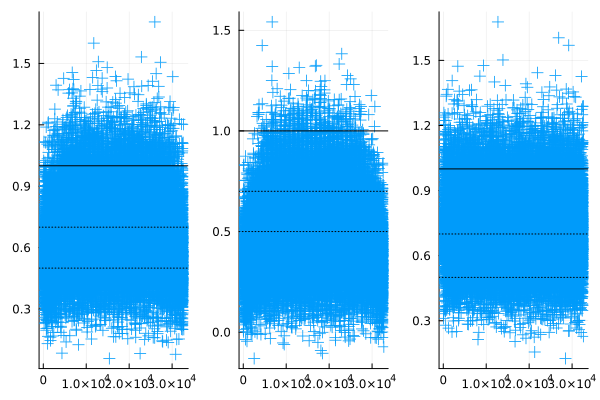

In [12]:
psis_plot_selec = Plots.scatter(pareto_shapes_selec; marker =:+, markersize=6, legend = false, linewidth=2)
hline!([0.5,0.7], linestyle=:dot, color =:black)
hline!([1.0], linestyle=:solid, color=:black)

psis_plot_selec2 = Plots.scatter(pareto_shapes_selec2; marker =:+, markersize=6, legend = false, linewidth=2)
hline!([0.5,0.7], linestyle=:dot, color =:black)
hline!([1.0], linestyle=:solid, color=:black)

psis_plot_miss3s = Plots.scatter(pareto_shapes_miss3s; marker =:+, markersize=6, legend = false, linewidth=2)
hline!([0.5,0.7], linestyle=:dot, color =:black)
hline!([1.0], linestyle=:solid, color=:black)

Plots.plot(psis_plot_selec, psis_plot_selec2, psis_plot_miss3s, layout = (1, 3))

The plot above is of the Pareto shape parameters from PSIS. Because the shape parameters are all under the threshhold of 0.5, this informs that the importance sampling is well-behaved and reliable for probability reweighting in the Leave One Out approach.

Now that we know the weights are reliable, we can proceed with the LOO-PIT analysis. The PSIS weights inform how to reweight $p(y | \theta)$ determined by the MCMC logpdf_mesh field, into $p(y_{-i} | \theta)$, the LOO probability density. 

First load the logcdf_mesh field from the MCMC chain file. Similar to logpdf_mesh, this field has contains 4 x 512 samples corresponding to the CDF of that particular voxel. It is stored below in an array with each voxel having an array of all CDF samples

In [14]:
logcdf_mesh_selec = Array{Vector{Float64}}(undef, 32, 32, 32)
logcdf_mesh_selec2 = Array{Vector{Float64}}(undef, 32, 32, 32)
logcdf_mesh_miss3s = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logcdf_mesh_selec[i,j,k] = []
    logcdf_mesh_selec2[i,j,k] = []
    logcdf_mesh_miss3s[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logcdf_mesh_selec[i,j,k], vec(f["logcdf_mesh"][:,:,i,j,k]))
    append!(logcdf_mesh_selec2[i,j,k], vec(g["logcdf_mesh"][:,:,i,j,k]))
    append!(logcdf_mesh_miss3s[i,j,k], vec(h["logcdf_mesh"][:,:,i,j,k]))
end

In [15]:
logcdf_mesh_selec

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-1.38924, -1.23152, -0.497576, -0.617985, -0.704375, -1.45387, -1.87113, -3.1698, -0.937588, -1.82564  …  -1.08336, -0.377775, -0.625694, -0.235971, -2.49328, -1.26299, -0.534909, -1.00286, -0.274903, -0.975731]                         …  [-0.13194, -0.829681, -1.39703, -0.911661, -0.935119, -1.11764, -0.159375, -0.492628, -1.2182, -0.550193  …  -0.472626, -0.640669, -0.57067, -0.26903, -0.922508, -0.807605, -1.5537, -1.11971, -0.617759, -0.676246]
 [-2.63191, -0.771659, -1.81668, -0.607439, -2.23001, -1.85349, -2.26561, -1.27183, -2.56987, -0.6402  …  -0.770186, -3.04701, -0.643741, -2.29012, -3.45937, -1.3777, -1.3361, -1.38306, -2.32666, -2.32714]                                    [-2.62824, -0.44944, -0.0571795, -0.017371, -1.16084, -0.134746, -0.467025, -0.247952, -1.30636, -0.609052  …  -0.935476, -0.700008, -0.520156, -0.443922, -0.0595918, -1.72299, -0.978731, -0.171441, -0.927872, -0.399521]
 [-0.806928, -0.123639, -0.378255, 

The CDF values are then able to be systemically reweighted by the PSIS weights in order to obtain the LOO-PIT final values.

In [16]:
loo_pit_selec = Array{Float64}(undef, 32, 32, 32)
loo_pit_selec2 = Array{Float64}(undef, 32, 32, 32)
loo_pit_miss3s = Array{Float64}(undef, 32, 32, 32)

for i in 1:32
    for j in 1:32
        for k in 1:32
            loo_pit_selec[i,j,k] = dot(psis_weights_selec[i,j,k], exp.(logcdf_mesh_selec[i,j,k]))
            loo_pit_selec2[i,j,k] = dot(psis_weights_selec2[i,j,k], exp.(logcdf_mesh_selec2[i,j,k]))
            loo_pit_miss3s[i,j,k] = dot(psis_weights_miss3s[i,j,k], exp.(logcdf_mesh_miss3s[i,j,k]))
        end
    end
end

Plotting the LOO-PIT values in a histogram, we see the approximately uniform distribution of values as expected from a MCMC sampling based on a strong model.

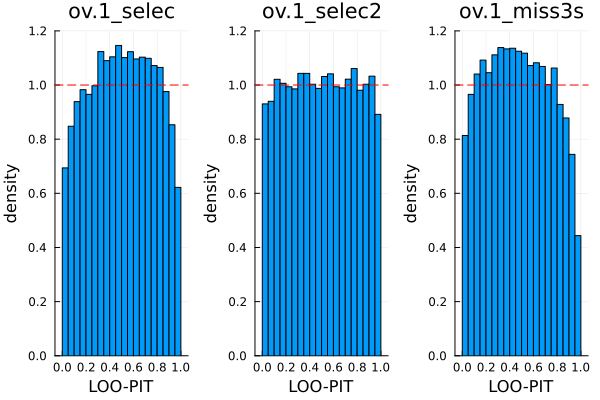

In [17]:
loo_pit_histogram_selec = Plots.histogram(vec(loo_pit_selec), legend=false, bins=20, normalize=:pdf, 
                                            ylims=(0,1.2), xticks=0:0.2:1.2, yticks=0:0.2:1.2, title="ov.1_selec", xaxis="LOO-PIT", yaxis="density")
hline!([1], color=:red, linestyle=:dash)

loo_pit_histogram_selec2 = Plots.histogram(vec(loo_pit_selec2), legend=false, bins=20, normalize=:pdf, 
                                            ylims=(0,1.2), xticks=0:0.2:1.2, yticks=0:0.2:1.2, title="ov.1_selec2", xaxis="LOO-PIT", yaxis="density")
hline!([1], color=:red, linestyle=:dash)

loo_pit_histogram_miss3s = Plots.histogram(vec(loo_pit_miss3s), legend=false, bins=20, normalize=:pdf, 
                                            ylims=(0,1.2), xticks=0:0.2:1.2, yticks=0:0.2:1.2, title="ov.1_miss3s", xaxis="LOO-PIT", yaxis="density")
hline!([1], color=:red, linestyle=:dash)

Plots.plot(loo_pit_histogram_selec, loo_pit_histogram_selec2, loo_pit_histogram_miss3s, layout = (1, 3))

WORK IN PROGRESS


In [20]:
loo_pit_zavg_selec = Matrix{Float64}(undef, 32, 32)
loo_pit_zavg_selec2 = Matrix{Float64}(undef, 32, 32)
loo_pit_zavg_miss3s = Matrix{Float64}(undef, 32, 32)

for i in 1:32
    for j in 1:32
        total_selec = 0
        total_selec2 = 0
        total_miss3s = 0
        for k in 1:32
            total_selec += loo_pit_selec[i,j,k]
            total_selec2 += loo_pit_selec2[i,j,k]
            total_miss3s += loo_pit_miss3s[i,j,k]
        end
        loo_pit_zavg_selec[i,j] = total_selec / 32
        loo_pit_zavg_selec2[i,j] = total_selec2 / 32
        loo_pit_zavg_miss3s[i,j] = total_miss3s / 32
    end
end

In [21]:
clims_loo_pit_heatmap = extrema(filter(isfinite, vcat(
    vec(loo_pit_zavg_selec),
    vec(loo_pit_zavg_selec2),
    vec(loo_pit_zavg_miss3s)  
)))

(0.334646763068119, 0.6363830292841894)

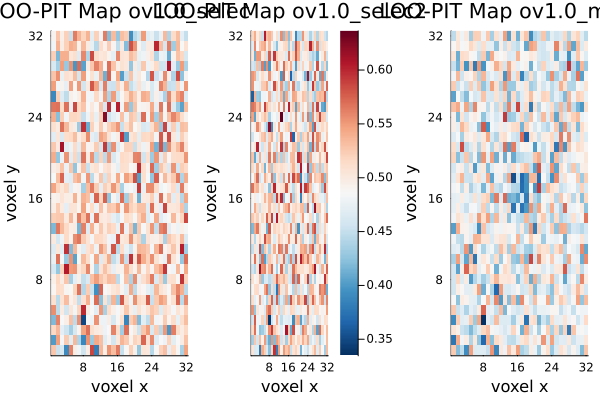

In [22]:
loo_pit_heatmap_selec = heatmap(loo_pit_zavg_selec, c=cgrad(:RdBu, rev=true), clims=clims_loo_pit_heatmap, colorbar=false, 
                                    title="LOO-PIT Map ov1.0_selec", xaxis="voxel x", yaxis="voxel y", xticks=0:8:32, yticks=0:8:32)

loo_pit_heatmap_selec2 = heatmap(loo_pit_zavg_selec2, c=cgrad(:RdBu, rev=true), clims=clims_loo_pit_heatmap, colorbar=true, 
                                    title="LOO-PIT Map ov1.0_selec2", xaxis="voxel x", yaxis="voxel y", xticks=0:8:32, yticks=0:8:32)
                                    
loo_pit_heatmap_miss3s = heatmap(loo_pit_zavg_miss3s, c=cgrad(:RdBu, rev=true), clims=clims_loo_pit_heatmap, colorbar=false, 
                                    title="LOO-PIT Map ov1.0_miss3s", xaxis="voxel x", yaxis="voxel y", xticks=0:8:32, yticks=0:8:32)

Plots.plot(loo_pit_heatmap_selec, loo_pit_heatmap_selec2, loo_pit_heatmap_miss3s, layout = (1, 3))

In [23]:
f = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/SelectionTestData/self_ov1.0_selec/count_mesh.npz")
g = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/SelectionTestData/self_ov1.0_selec2/count_mesh.npz")
h = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/SelectionTestData/miss3s_ov1.0/count_mesh.npz")

Dict{String, Array{Float64, 3}} with 1 entry:
  "count_mesh" => [210.206 258.468 … 231.184 210.511; 190.385 258.594 … 187.595…

In [24]:
count_mesh_selec = f["count_mesh"]
count_mesh_selec2 = g["count_mesh"]
count_mesh_miss3s = h["count_mesh"]

32×32×32 Array{Float64, 3}:
[:, :, 1] =
 210.206  258.468  244.47   183.74   …  202.15   175.607  231.184  210.511
 190.385  258.594  227.754  190.888     259.575  186.712  187.595  223.895
 223.078  175.332  185.462  234.677     271.301  200.775  213.011  231.383
 170.881  180.762  203.046  170.215     236.243  151.383  196.447  163.522
 231.927  198.994  211.022  196.718     193.058  179.212  196.176  230.028
 225.863  180.464  205.472  188.839  …  207.002  238.64   196.725  161.85
 150.311  170.948  184.991  180.507     222.202  322.551  247.652  182.28
 220.473  166.286  212.246  212.188     230.437  234.175  279.286  231.269
 178.651  116.263  154.753  234.776     195.764  175.901  244.669  241.193
 280.604  203.345  147.312  228.464     163.733  222.501  245.127  263.421
   ⋮                                 ⋱                      ⋮      
 229.925  207.832  178.54   192.942     227.211  279.598  167.356  201.376
 276.134  229.398  185.693  218.685     197.063  177.166  222.872  21

In [25]:
along_losz_selec = Matrix{Float64}(undef, 32, 32)
along_losz_selec2 = Matrix{Float64}(undef, 32, 32)
along_losz_miss3s = Matrix{Float64}(undef, 32, 32)

for i in 1:32
    for j in 1:32
        total_selec = 0
        total_selec2 = 0
        total_miss3s = 0
        for k in 1:32
            total_selec += count_mesh_selec[i,j,k]
            total_selec2 += count_mesh_selec2[i,j,k]
            total_miss3s += count_mesh_miss3s[i,j,k]
        end
        along_losz_selec[i,j] = total_selec / 32
        along_losz_selec2[i,j] = total_selec2 / 32
        along_losz_miss3s[i,j] = total_miss3s / 32
    end
end

In [26]:
clims_count_heatmap = extrema(filter(isfinite, vcat(
    vec(along_losz_selec),
    vec(along_losz_selec2),
    vec(along_losz_miss3s)  
)))

(12.903613851002511, 465.06338529027863)

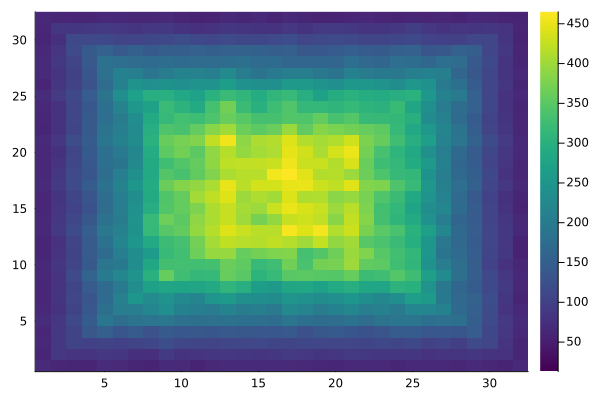

In [27]:
heatmap(along_losz_selec, c=:viridis, clims=clims_count_heatmap)

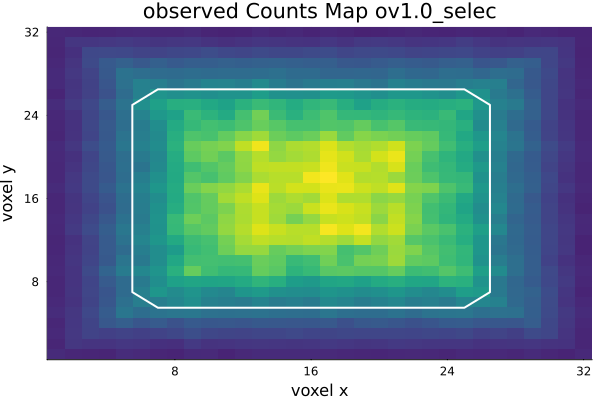

In [28]:
using Plots

# ---------------------------------------------------------
# Heatmap
# ---------------------------------------------------------

heatmap_selec = heatmap(along_losz_selec, c=:viridis, clims=clims_count_heatmap, colorbar=false,
                            title="observed Counts Map ov1.0_selec", xaxis="voxel x", yaxis="voxel y", xticks=0:8:32, yticks=0:8:32,
                            xlims=(0.5, size(along_losz_selec, 2) + 0.5), ylims=(0.5, size(along_losz_selec, 1) + 0.5), margin=0Plots.mm)


# ---------------------------------------------------------
# Half maximum
# ---------------------------------------------------------

halfmax = maximum(along_losz_selec) / 2

# Find pixels above half maximum
inds = findall(along_losz_selec .>= halfmax)

xs = [I[1] for I in inds]
ys = [I[2] for I in inds]

xmin, xmax = extrema(xs)
ymin, ymax = extrema(ys)


# ---------------------------------------------------------
# Make bounding region square
# ---------------------------------------------------------

width = max(xmax - xmin, ymax - ymin)

cx = (xmin + xmax) / 2
cy = (ymin + ymax) / 2

xmin = cx - width / 2
xmax = cx + width / 2
ymin = cy - width / 2
ymax = cy + width / 2


# ---------------------------------------------------------
# Convert pixel-center coordinates to pixel-edge coordinates
# ---------------------------------------------------------

xmin_edge = xmin - 0.5
xmax_edge = xmax + 0.5
ymin_edge = ymin - 0.5
ymax_edge = ymax + 0.5


# ---------------------------------------------------------
# Corner cut size
# ---------------------------------------------------------

c = 1.5


# ---------------------------------------------------------
# Octagonal boundary
# ---------------------------------------------------------

x = [
    xmin_edge + c,
    xmax_edge - c,
    xmax_edge,
    xmax_edge,
    xmax_edge - c,
    xmin_edge + c,
    xmin_edge,
    xmin_edge,
    xmin_edge + c
]

y = [
    ymin_edge,
    ymin_edge,
    ymin_edge + c,
    ymax_edge - c,
    ymax_edge,
    ymax_edge,
    ymax_edge - c,
    ymin_edge + c,
    ymin_edge
]


# ---------------------------------------------------------
# Overlay boundary
# ---------------------------------------------------------

plot!(
    heatmap_selec,
    x,
    y,
    color=:white,
    linewidth=2,
    label=false
)


# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

display(heatmap_selec)

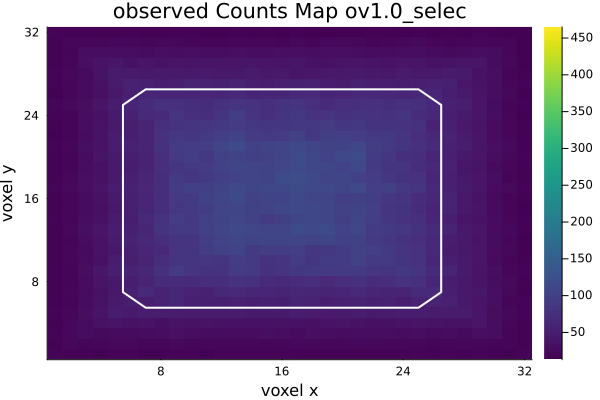

In [29]:
heatmap_selec2 = heatmap(along_losz_selec2, c=:viridis, clims=clims_count_heatmap, colorbar=true,
                            title="observed Counts Map ov1.0_selec", xaxis="voxel x", yaxis="voxel y", xticks=0:8:32, yticks=0:8:32,
                            xlims=(0.5, size(along_losz_selec, 2) + 0.5), ylims=(0.5, size(along_losz_selec, 1) + 0.5), margin=0Plots.mm)

plot!(
    x,
    y,
    color=:white,
    linewidth=2,
    label=false
)

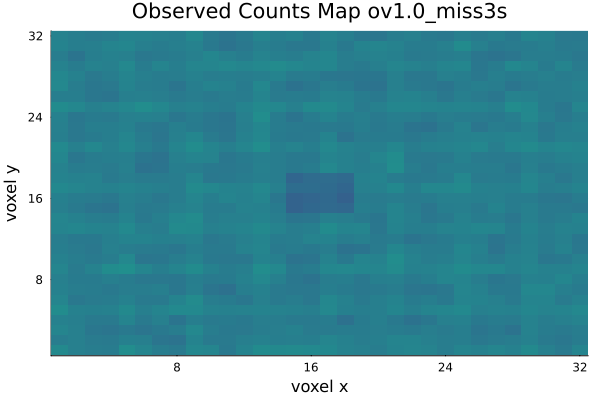

In [30]:
heatmap_miss3s = heatmap(along_losz_miss3s, c=:viridis, clims=clims_count_heatmap, colorbar=false,
                            title="Observed Counts Map ov1.0_miss3s", xaxis="voxel x", yaxis="voxel y", xticks=0:8:32, yticks=0:8:32)

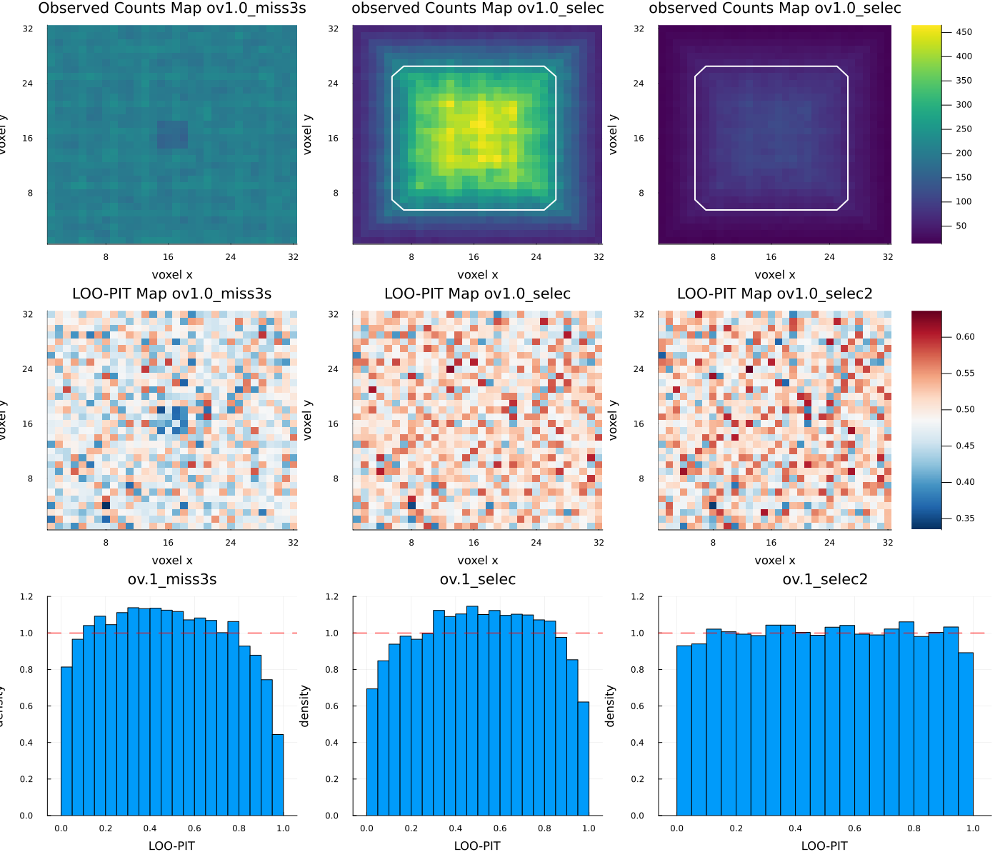

In [32]:
using Plots

# ─────────────────────────────────────────────
# Row 1: heatmaps — shared colour scale
# ─────────────────────────────────────────────
p11 = heatmap_selec 
p12 = heatmap_selec2
p13 = heatmap_miss3s


# ─────────────────────────────────────────────
# Row 2: heatmaps — shared colour scale
# ─────────────────────────────────────────────

p21 = loo_pit_heatmap_selec
p22 = loo_pit_heatmap_selec2
p23 = loo_pit_heatmap_miss3s


# ─────────────────────────────────────────────
# Row 3: histograms — shared y-axis
# ─────────────────────────────────────────────

p31 = loo_pit_histogram_selec
p32 = loo_pit_histogram_selec2
p33 = loo_pit_histogram_miss3s


# ─────────────────────────────────────────────
# Combine
# ─────────────────────────────────────────────

layout = @layout [
    a{0.3w} b{0.3w} c{0.4w}
    d{0.3w} e{0.3w} f{0.4w}
    g{0.3w} h{0.3w} i{0.4w}
]

Plots.plot(
    p13, p11, p12,
    p23, p21, p22,
    p33, p31, p32;
    layout=layout,
    size=(1400, 1200)
)